## **Explanatory Data Analysis (EDA)** ##

In [1]:
# Import libraries needed
import numpy as np
import pandas as pd

# For graph plot
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Tests
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen 
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
# Import data and settings
df = pd.read_csv("data.csv")

mete_col = ["Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)", "Air pressure (hPa)", "Dew point temperature (°C)", "Wind speed (km/h)", "Mean UV"]
flu_col = ["H1", "H3", "B", "AandB"]
control_col = ["Week", "ContainmentHealthIndex_Average", "pandemic_flag"]

In [3]:
# Quick overview of the data
df.head()

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,Population,Log_population,school_flag
0,2002,36,2002-09-01,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19,0.0,0.0,6725.8,8.813706,1.0
1,2002,37,2002-09-08,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15,0.0,0.0,6725.8,8.813706,1.0
2,2002,38,2002-09-15,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13,0.0,0.0,6725.8,8.813706,1.0
3,2002,39,2002-09-22,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10,0.0,0.0,6725.8,8.813706,1.0
4,2002,40,2002-09-29,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8,0.0,0.0,6725.8,8.813706,1.0


In [4]:
# Infromation of the DataFrmae
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1253 entries, 0 to 1252
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            1253 non-null   int64  
 1   Week                            1253 non-null   int64  
 2   From                            1253 non-null   object 
 3   Diurnal temperature range (°C)  1253 non-null   float64
 4   Mean temperature (°C)           1253 non-null   float64
 5   Mean humidity (%)               1253 non-null   float64
 6   Solar radiation (MJ/m²)         1253 non-null   float64
 7   Air pressure (hPa)              1253 non-null   float64
 8   Dew point temperature (°C)      1253 non-null   float64
 9   Wind speed (km/h)               1253 non-null   float64
 10  Mean UV                         1253 non-null   float64
 11  H1                              1253 non-null   int64  
 12  H3                              12

In [5]:
# Statistical information for the meteorological data
df[mete_col].describe()

,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,14.864006,23.383599,78.736233,13.996983,1012.860774,19.225339,10.074062,2.891700
std,3.539967,5.005770,8.494599,5.270534,6.067874,5.963239,1.811932,1.256406
min,3.900000,8.900000,43.000000,2.020000,996.750000,-0.100000,5.550000,0.400000
25%,12.200000,19.100000,74.500000,9.930000,1008.000000,14.900000,8.800000,2.000000
50%,14.000000,24.400000,80.000000,14.240000,1012.800000,20.500000,10.000000,3.000000
75%,17.000000,28.000000,85.000000,17.680000,1017.650000,24.800000,11.200000,4.000000
max,27.700000,31.700000,94.000000,26.460000,1027.700000,26.800000,17.800000,7.000000


In [6]:
# Statistical information for the influenza data
df[flu_col].describe()

,H1,H3,B,AandB
count,1253.000000,1253.000000,1252.000000,1253.000000
mean,69.613727,115.727055,44.593450,261.437350
std,189.083854,233.728958,131.615377,439.621172
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,5.000000,3.000000,27.000000
50%,4.000000,28.000000,12.500000,103.000000
75%,47.000000,125.000000,41.000000,305.000000
max,1999.000000,2560.000000,1978.000000,4679.000000


In [7]:
# Statistical information for the control variables 
df[control_col].describe()

,Week,ContainmentHealthIndex_Average,pandemic_flag
count,1253.000000,1253.000000,1253.000000
mean,26.605746,8.128132,0.131684
std,15.077257,21.983305,0.338282
min,1.000000,0.000000,0.000000
25%,14.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000
75%,40.000000,0.000000,0.000000
max,53.000000,82.140000,1.000000


In [8]:
# Check missing values in each columns
print(f"Number of NA values in each rows: \n{df.isna().sum()}")

Number of NA values in each rows: 
Year                              0
Week                              0
From                              0
Diurnal temperature range (°C)    0
Mean temperature (°C)             0
Mean humidity (%)                 0
Solar radiation (MJ/m²)           0
Air pressure (hPa)                0
Dew point temperature (°C)        0
Wind speed (km/h)                 0
Mean UV                           0
H1                                0
H3                                0
B                                 1
AandB                             0
ContainmentHealthIndex_Average    0
pandemic_flag                     0
Population                        0
Log_population                    0
school_flag                       0
dtype: int64


In [9]:
# Check how many 0 exists in the target variables
(df[flu_col]==0).sum()

H1       472
H3       133
B        137
AandB     76
dtype: int64

C:\Users\yanss\AppData\Local\Temp\ipykernel_40628\2639280369.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i//2, i%2].set_xticklabels([">0", "0"])
C:\Users\yanss\AppData\Local\Temp\ipykernel_40628\2639280369.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i//2, i%2].set_xticklabels([">0", "0"])
C:\Users\yanss\AppData\Local\Temp\ipykernel_40628\2639280369.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i//2, i%2].set_xticklabels([">0", "0"])
C:\Users\yanss\AppData\Local\Temp\ipykernel_40628\2639280369.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i//2, i%2].set_xticklabels([">0", "0"])


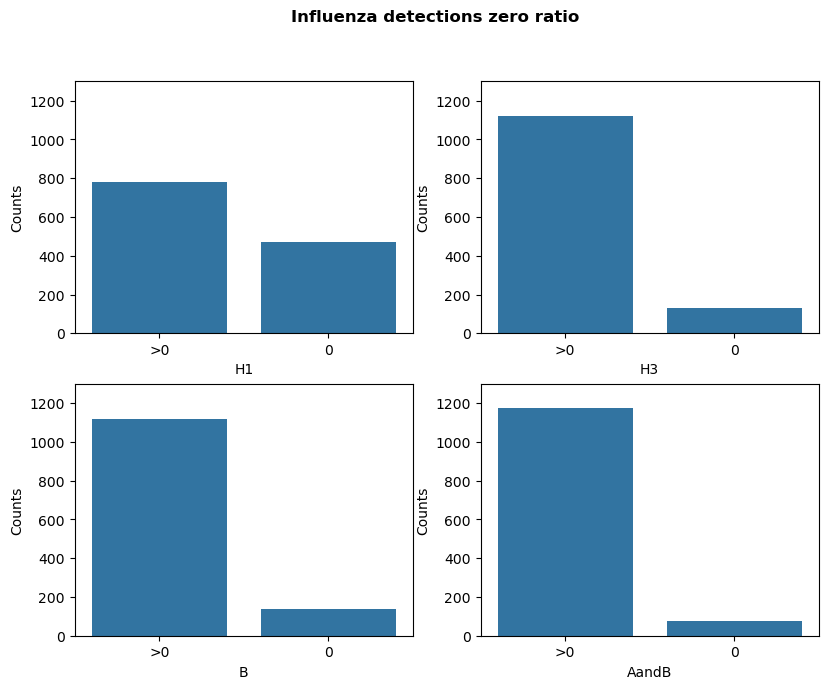

In [10]:
# Visualize the ratio of counts
fig, axes = plt.subplots(2, 2, figsize=(6.4*1.5, 4.8*1.5))

for i, col in enumerate(flu_col):
    temp_df = pd.DataFrame(df[col], columns=[col])
    temp_df["zero_flag"] = (temp_df[col]==0).astype(int)
    sns.barplot(data=temp_df["zero_flag"].value_counts(), ax=axes[i//2, i%2])
    axes[i//2, i%2].set_xticklabels([">0", "0"])
    axes[i//2, i%2].set_xlabel(col)
    axes[i//2, i%2].set_ylabel("Counts")
    axes[i//2, i%2].set_ylim(0, 1300)

plt.suptitle("Influenza detections zero ratio", fontweight="bold")
plt.show()

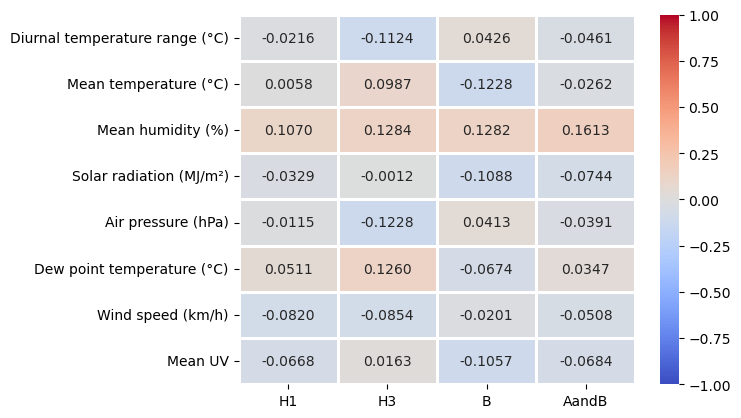

In [11]:
# correlation between meteorlogical factors and influenza detections
corr_df = df.drop(["Year", "Week", "From"], axis=1).corr(method="spearman")
corr_df = corr_df.loc[mete_col, flu_col]

sns.heatmap(corr_df, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".4f", linewidth=1)
plt.show()

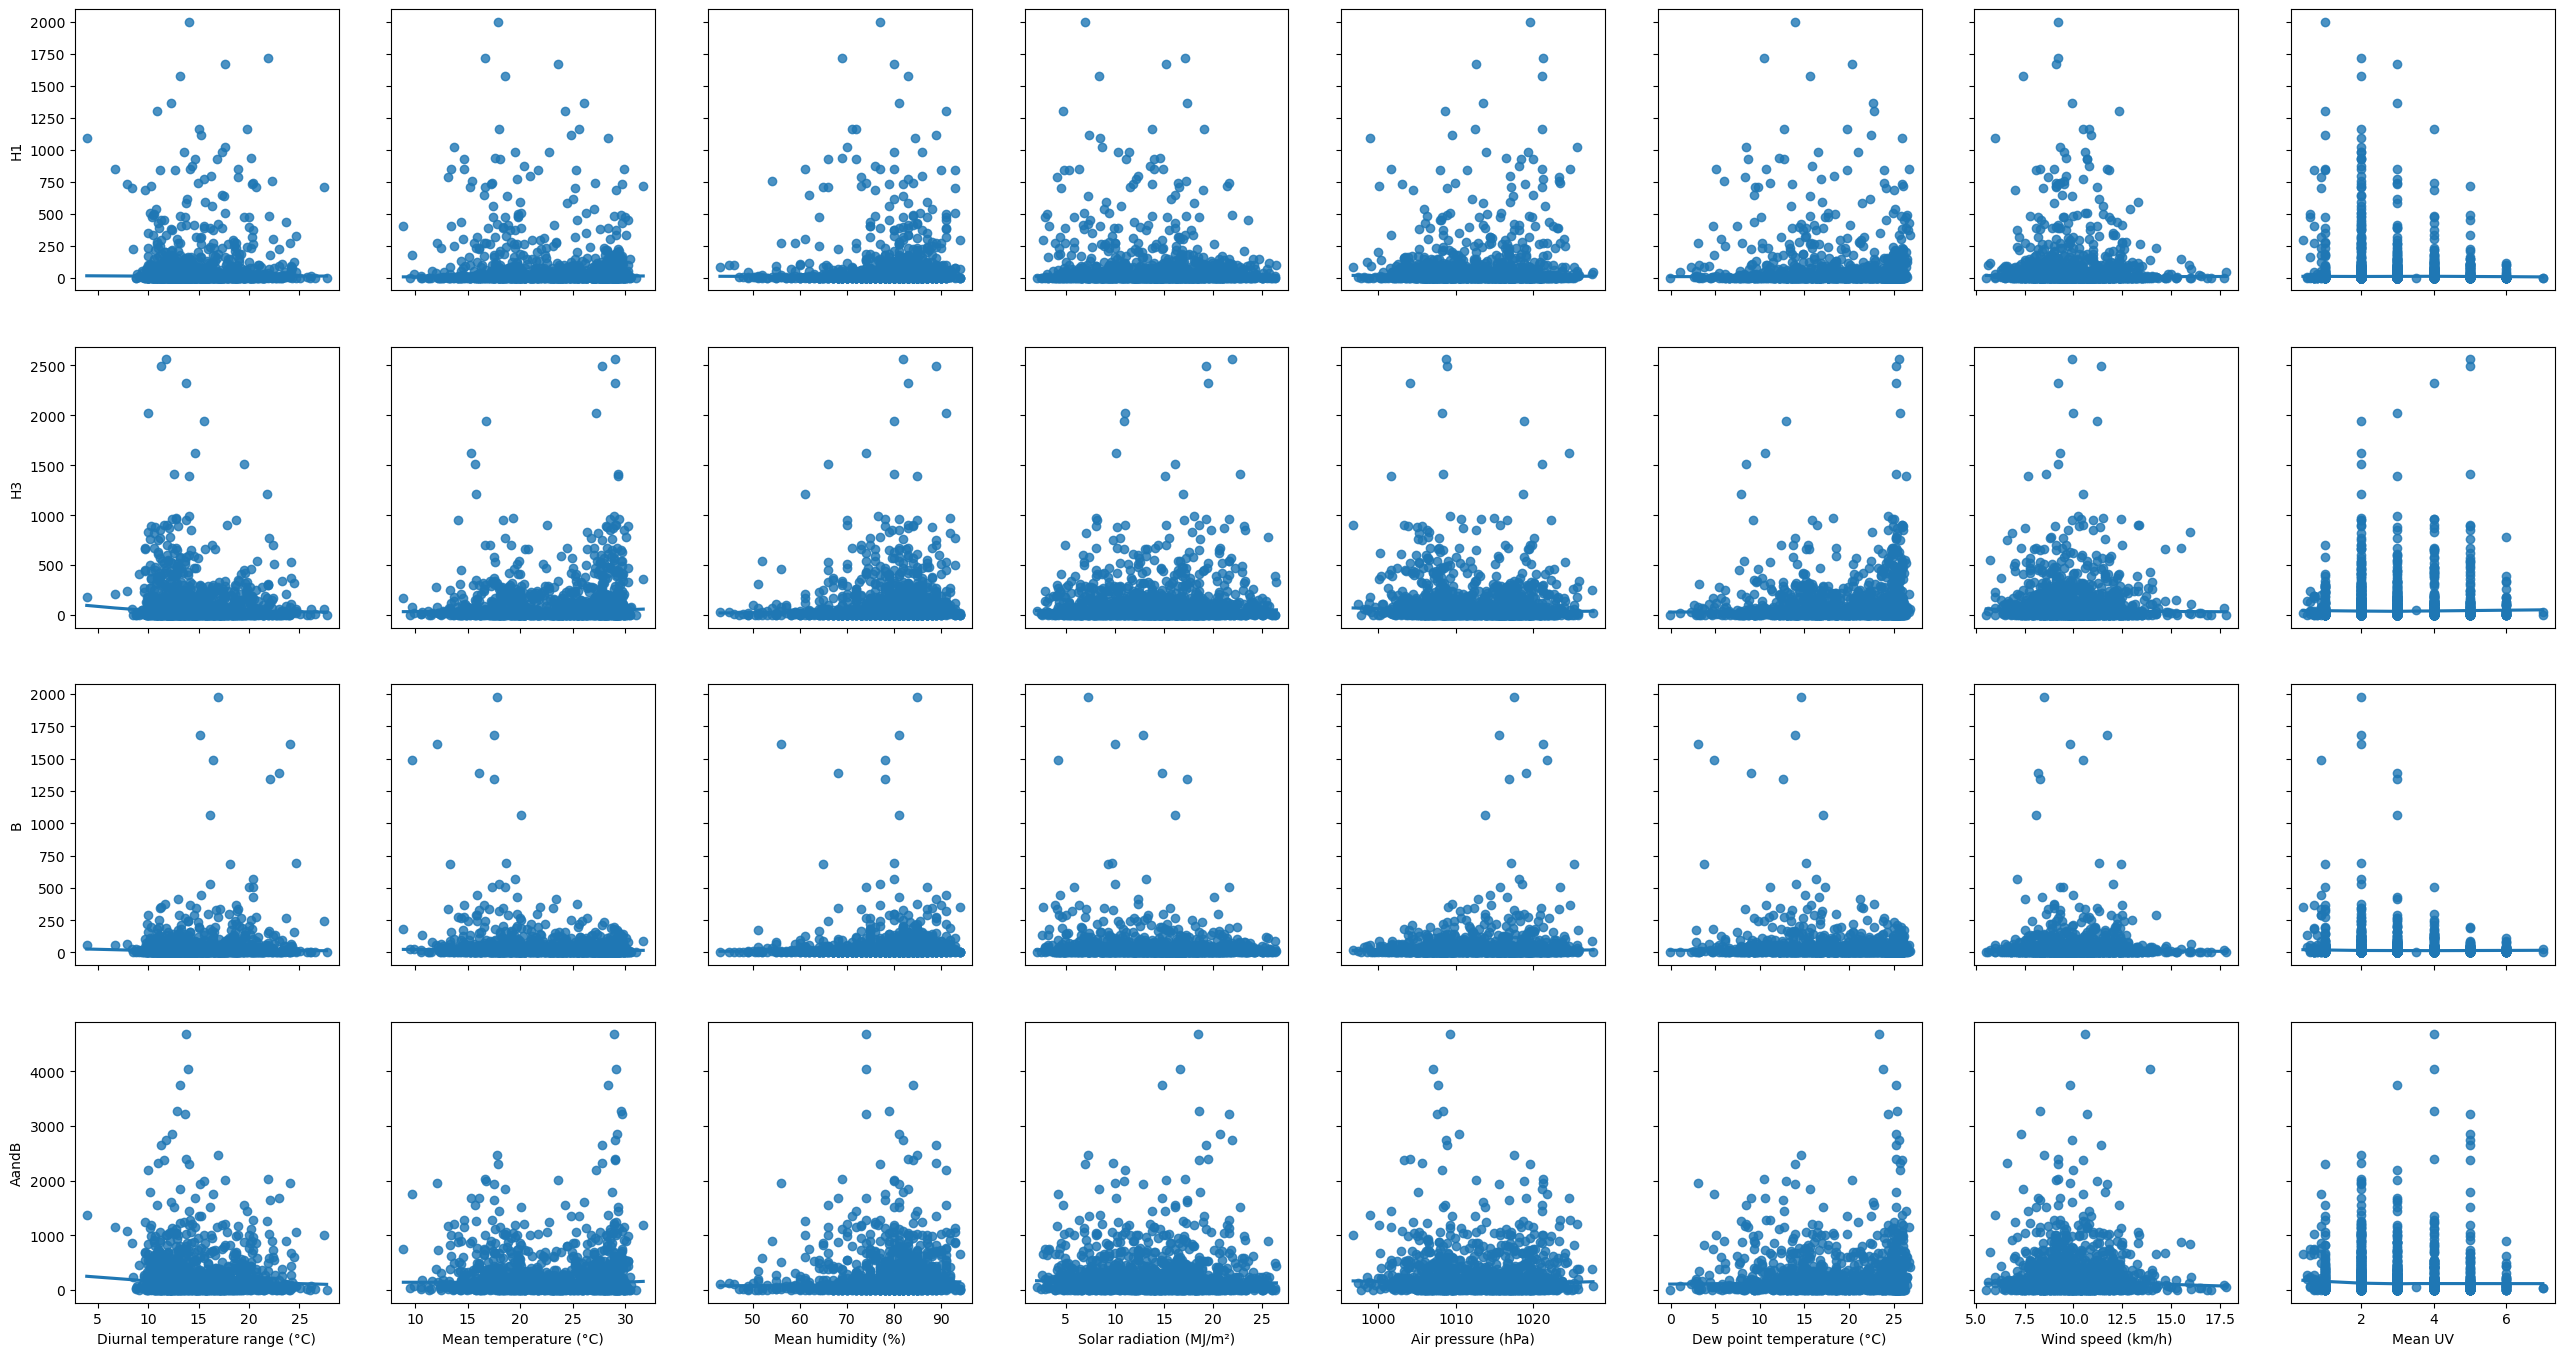

In [12]:
fig, axes = plt.subplots(4, 8, figsize=(6.4*5, 4.8*3.5))

for i, flu in enumerate(flu_col):
    for j, mete in enumerate(mete_col):
        sns.regplot(x=mete, y=flu, data=df, ax=axes[i, j], lowess=True)
        axes[i, j].set_xlabel(mete)
        axes[i, j].set_ylabel(flu)
        axes[i, j].label_outer()
        
plt.show()   


In [13]:
df_long = df.melt(
    id_vars=["From"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

fig = px.line(df_long, "From", "Influenza detections", color="Type",
              title="Number of detections based on timeline", 
              width=1500, height=600
             )

fig.show()

In [14]:
cols = mete_col
colors = ["#e15759","#b89b28","#59a14f","#1b9e77","#17a7e0","#8e7cc3","#e754a8"]
n = len(cols)

fig = make_subplots(
    rows=n, cols=1,
    shared_xaxes=True,
    vertical_spacing=0.02,
    specs=[[{"secondary_y": True}] for _ in range(n)],
)

for i, col in enumerate(cols, start=1):
    color = colors[(i - 1) % len(colors)]

    fig.add_trace(
        go.Scatter(
            x=df["From"], y=df[col], name=col,
            mode="lines",
            line={"color": color, "width": 1.2},
            showlegend=True,
        ),
        row=i, col=1, secondary_y=False
    )

    fig.update_yaxes(
        row=i, col=1,
        secondary_y=False,
        showgrid=True, gridcolor="rgba(220, 220, 220, 0.7)",
        showline=True, linecolor="#888888",
        tickfont={"size": 10}
    )

    fig.update_yaxes(
        row=i, col=1, secondary_y=True,
        title_text=col, title_font={"size": 11, "color": "black"},
        showticklabels=False,
        showgrid=False,
        showline=True, linecolor="#888888"
    )

    fig.update_xaxes(
        row=i, col=1,
        showgrid=True, gridcolor="rgba(220, 220, 220, 0.7)",
        showline=True, linecolor="#888888",
        tickformat="%Y" if i == n else None, showticklabels=(i == n),
    )

fig.update_layout(
    title="Meteorological values based on timeline",
    width=1500, height=max(650, n * 100),
    plot_bgcolor="white",
    paper_bgcolor="white",
    margin={"l": 60, "r": 180, "t": 85, "b": 40},
    hovermode="x unified"
)

fig.add_annotation(
    text="Variables",
    x=-0.04, y=0.5,
    xref="paper", yref="paper",
    textangle=-90,
    font={"size": 13, "color": "black"},
)

fig.show()

Lagged correlation between the variables and type H1 influenxa case counts


,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
0,-0.021623,0.005841,0.106987,-0.032933,-0.011485,0.051058,-0.081967,-0.066776
1,-0.014022,-0.013862,0.090023,-0.031710,0.011252,0.030324,-0.088528,-0.075601
2,-0.000695,-0.033757,0.087936,-0.048376,0.028835,0.014261,-0.082179,-0.088247
3,0.018079,-0.049189,0.072279,-0.057292,0.042608,-0.003512,-0.085423,-0.106629
4,0.027962,-0.063886,0.054625,-0.061982,0.063480,-0.019892,-0.085369,-0.113111


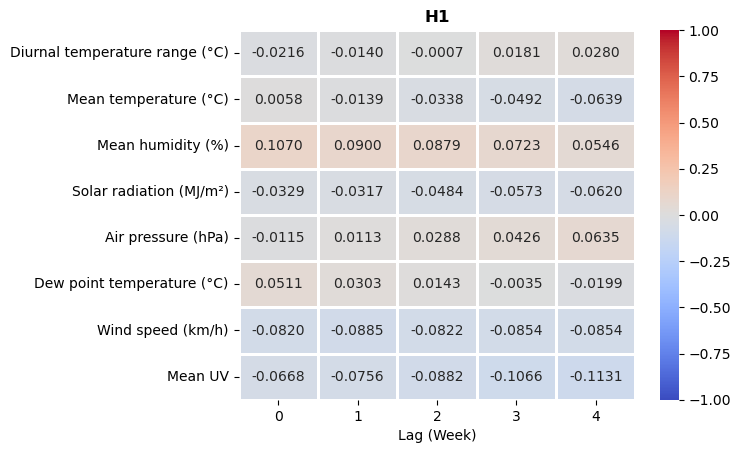

Lagged correlation between the variables and type H3 influenxa case counts


,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
0,-0.112394,0.098653,0.128419,-0.001178,-0.122832,0.125961,-0.085351,0.016252
1,-0.114987,0.082121,0.135955,-0.018351,-0.112762,0.116619,-0.091806,0.000212
2,-0.110677,0.066177,0.141784,-0.030888,-0.104786,0.109094,-0.083208,-0.010408
3,-0.101493,0.049804,0.136490,-0.044481,-0.094153,0.094441,-0.080112,-0.028831
4,-0.088209,0.032858,0.127797,-0.045214,-0.074149,0.077667,-0.076587,-0.039421


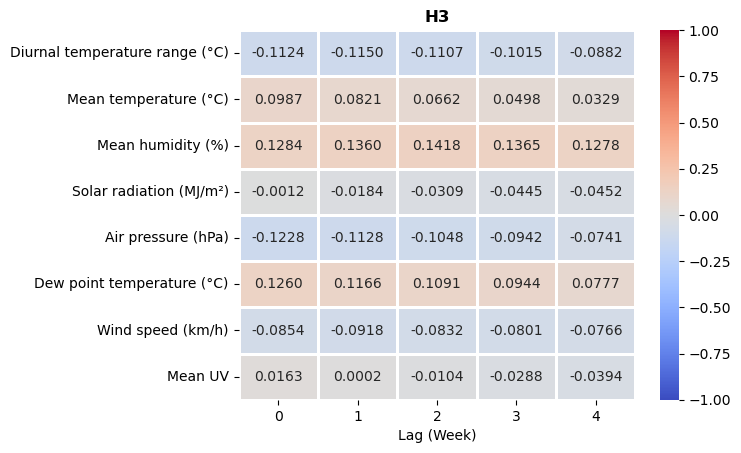

Lagged correlation between the variables and type B influenxa case counts


,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
0,0.042635,-0.122834,0.128242,-0.108846,0.041290,-0.067376,-0.020075,-0.105686
1,0.077294,-0.163524,0.113253,-0.118373,0.085566,-0.105940,-0.035987,-0.125850
2,0.099684,-0.202250,0.097356,-0.155873,0.120645,-0.141645,-0.008557,-0.164896
3,0.124535,-0.231607,0.082728,-0.169229,0.152236,-0.170034,-0.009127,-0.189838
4,0.151164,-0.263680,0.064379,-0.183217,0.188668,-0.200839,-0.008465,-0.220330


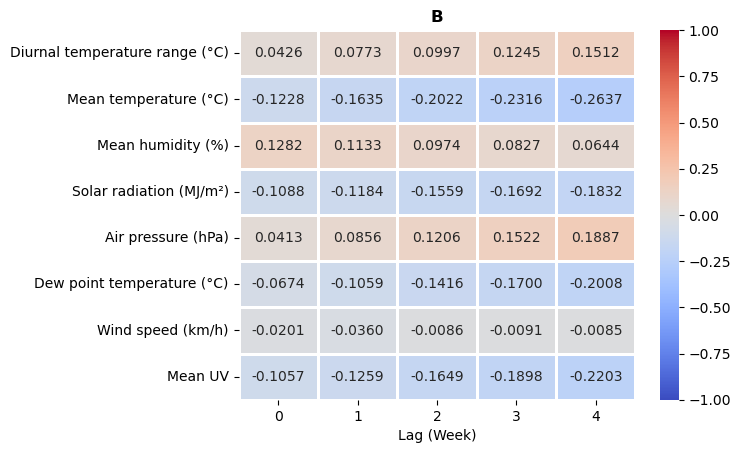

Lagged correlation between the variables and type AandB influenxa case counts


,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
0,-0.046062,-0.026245,0.161329,-0.074390,-0.039052,0.034729,-0.050803,-0.068360
1,-0.037752,-0.059409,0.153734,-0.097825,-0.008690,0.005879,-0.060286,-0.097841
2,-0.019252,-0.090800,0.148737,-0.123748,0.019261,-0.019444,-0.048444,-0.127381
3,0.001840,-0.116745,0.128214,-0.137531,0.043815,-0.046366,-0.050720,-0.152100
4,0.025259,-0.143572,0.102241,-0.145158,0.077533,-0.075423,-0.051761,-0.172784


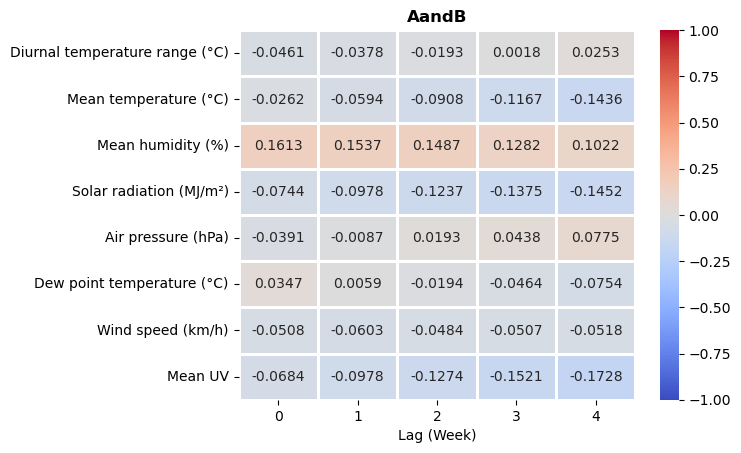

In [15]:
for flu in flu_col:
    corr_lst_lst = []
    for mete in mete_col:
        corr_lst = []
        lags = [0, 1, 2, 3, 4]
        for lag in lags:
            x_lagged = df[mete].shift(lag)
            temp = pd.concat([df[flu], x_lagged], axis=1).dropna()
            # Spearman rank correlation is used as the relationship is monotonic (i.e. non-normal)
            # pearson's r only measure linear relationship which is not sufficient 
            corr = temp[flu].corr(temp[mete], method="spearman")
            corr_lst.append(corr)
        corr_lst_lst.append(corr_lst)

    print(f"Lagged correlation between the variables and type {flu} influenxa case counts")
    display(pd.DataFrame(corr_lst_lst, index=mete_col).T)
    sns.heatmap(pd.DataFrame(corr_lst_lst, index=mete_col), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".4f", linewidth=1)
    plt.xlabel("Lag (Week)")
    plt.title(flu, fontweight="bold")
    plt.show()

In [16]:
# Test for stationarity with ADF test
for mete in mete_col:
    print(f"{mete} ADF p-value:", adfuller(df[mete].dropna(), result_object=False)[1])

for flu in flu_col:
    print(f"{flu} ADF p-value:", adfuller(df[flu].dropna(), result_object=False)[1])


Diurnal temperature range (°C) ADF p-value: 9.72706889039368e-24
Mean temperature (°C) ADF p-value: 2.1508674892395732e-24
Mean humidity (%) ADF p-value: 5.98549022678368e-18
Solar radiation (MJ/m²) ADF p-value: 5.64608784548384e-17
Air pressure (hPa) ADF p-value: 4.63618750842299e-28
Dew point temperature (°C) ADF p-value: 1.4552551550631437e-24
Wind speed (km/h) ADF p-value: 1.697348805767327e-26
Mean UV ADF p-value: 4.4678619714055217e-23
H1 ADF p-value: 1.3724247720784995e-12
H3 ADF p-value: 2.9996852009556233e-13
B ADF p-value: 3.746676484677444e-09
AandB ADF p-value: 2.6988637442982515e-11


In [17]:
# Test for cointegration 
for mete in mete_col:
    for flu in flu_col:
        score, pvalue, crit_values = coint(df[flu], df[mete])

        print(f"\n{mete} & {flu}:")
        print(f"Test Statistics: {score:.4f}")
        print(f"P-value: {pvalue:.4f}")
        print(f"Critical Value (1%, 5%, 10%): {crit_values}")


Diurnal temperature range (°C) & H1:
Test Statistics: -8.0683
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Diurnal temperature range (°C) & H3:
Test Statistics: -8.2723
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Diurnal temperature range (°C) & B:
Test Statistics: -inf
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Diurnal temperature range (°C) & AandB:
Test Statistics: -7.6230
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Mean temperature (°C) & H1:
Test Statistics: -7.4724
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Mean temperature (°C) & H3:
Test Statistics: -8.4436
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Mean temperature (°C) & B:
Test Statistics: -inf
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Me

C:\Users\yanss\AppData\Local\Temp\ipykernel_40628\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.

C:\Users\yanss\AppData\Local\Temp\ipykernel_40628\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.

C:\Users\yanss\AppData\Local\Temp\ipykernel_40628\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.

C:\Users\yanss\AppData\Local\Temp\ipykernel_40628\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.

C:\Users\yanss\AppData\Local\Temp\ipykernel_40628\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.




Air pressure (hPa) & H3:
Test Statistics: -7.2917
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Air pressure (hPa) & B:
Test Statistics: -inf
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Air pressure (hPa) & AandB:
Test Statistics: -7.5861
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Dew point temperature (°C) & H1:
Test Statistics: -8.1433
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Dew point temperature (°C) & H3:
Test Statistics: -7.3382
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Dew point temperature (°C) & B:
Test Statistics: -inf
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Dew point temperature (°C) & AandB:
Test Statistics: -7.5879
P-value: 0.0000
Critical Value (1%, 5%, 10%): [-3.90520891 -3.34101462 -3.04783928]

Wind speed (km/h) & H1:


C:\Users\yanss\AppData\Local\Temp\ipykernel_40628\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.

C:\Users\yanss\AppData\Local\Temp\ipykernel_40628\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.

C:\Users\yanss\AppData\Local\Temp\ipykernel_40628\2581919284.py:4: CollinearityWarning:

y0 and y1 are (almost) perfectly colinear.Cointegration test is not reliable in this case.



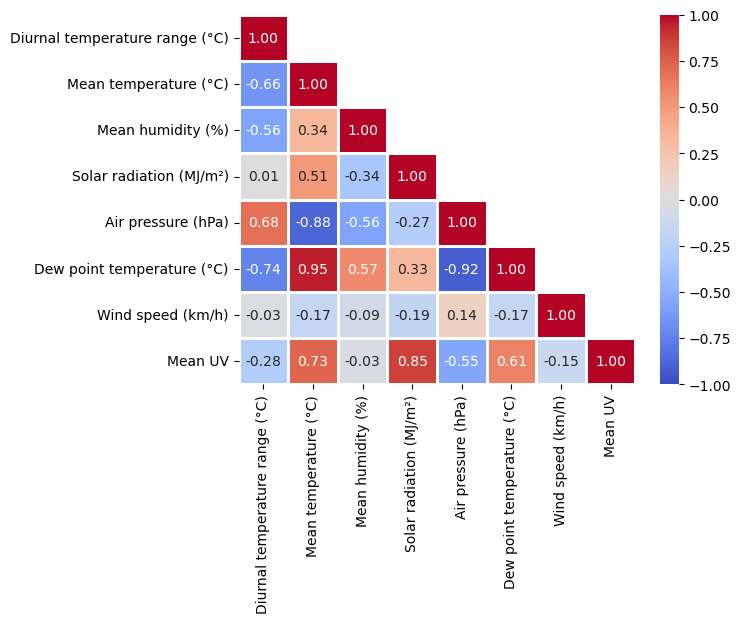

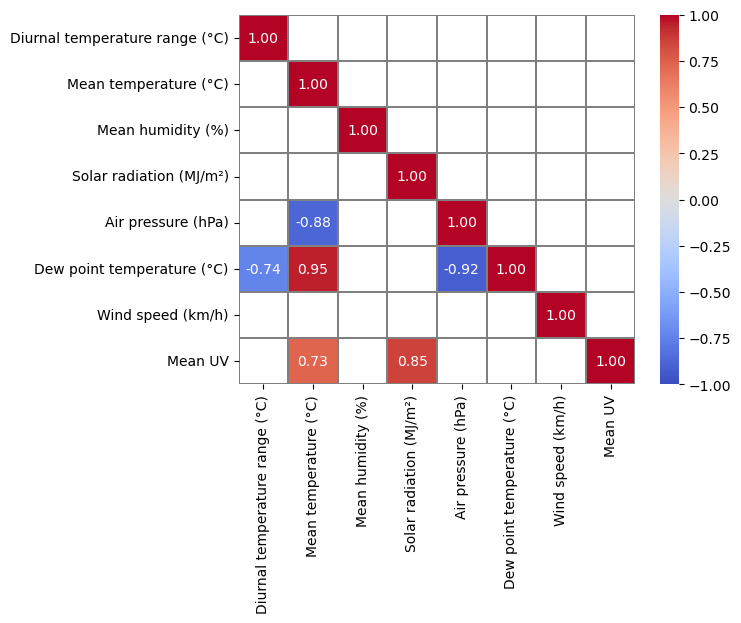

In [18]:
corr_weather = df[mete_col].corr(method="spearman")

for i in range(0, 8):
    for j in range(i+1, 8):
        corr_weather.iloc[i, j] = np.nan

sns.heatmap(corr_weather, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=1)
plt.show()

for i in range(7, 0, -1):
    for j in range(i-1, -1, -1):
            if ((corr_weather.iloc[i, j] < 0.7) and (corr_weather.iloc[i, j] > -0.7)):
                corr_weather.iloc[i, j] = np.nan


sns.heatmap(corr_weather, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=0.1, linecolor="gray")
plt.show()



In [19]:
# Test for mutlicollinearity with VIF
X = df[mete_col]

vif_df = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
}).sort_values("VIF", ascending=False)
display(vif_df)

while (vif_df["VIF"] > 5).any():
    mete_col.remove(vif_df.loc[0, "Variable"])
    X = df[mete_col]

    vif_df = pd.DataFrame({
        "Variable": X.columns,
        "VIF": [
            variance_inflation_factor(X.values, i)
            for i in range(X.shape[1])
        ]
    }).sort_values("VIF", ascending=False)

display(vif_df)
print(f"Final mete list: {mete_col}")


,Variable,VIF
5,Dew point temperature (°C),134.747528
1,Mean temperature (°C),95.874813
2,Mean humidity (%),17.686105
3,Solar radiation (MJ/m²),7.610842
7,Mean UV,7.298033
4,Air pressure (hPa),5.342290
0,Diurnal temperature range (°C),2.442852
6,Wind speed (km/h),1.141350


,Variable,VIF
2,Mean UV,1.470198
0,Dew point temperature (°C),1.465568
1,Wind speed (km/h),1.017486


Final mete list: ['Dew point temperature (°C)', 'Wind speed (km/h)', 'Mean UV']


---

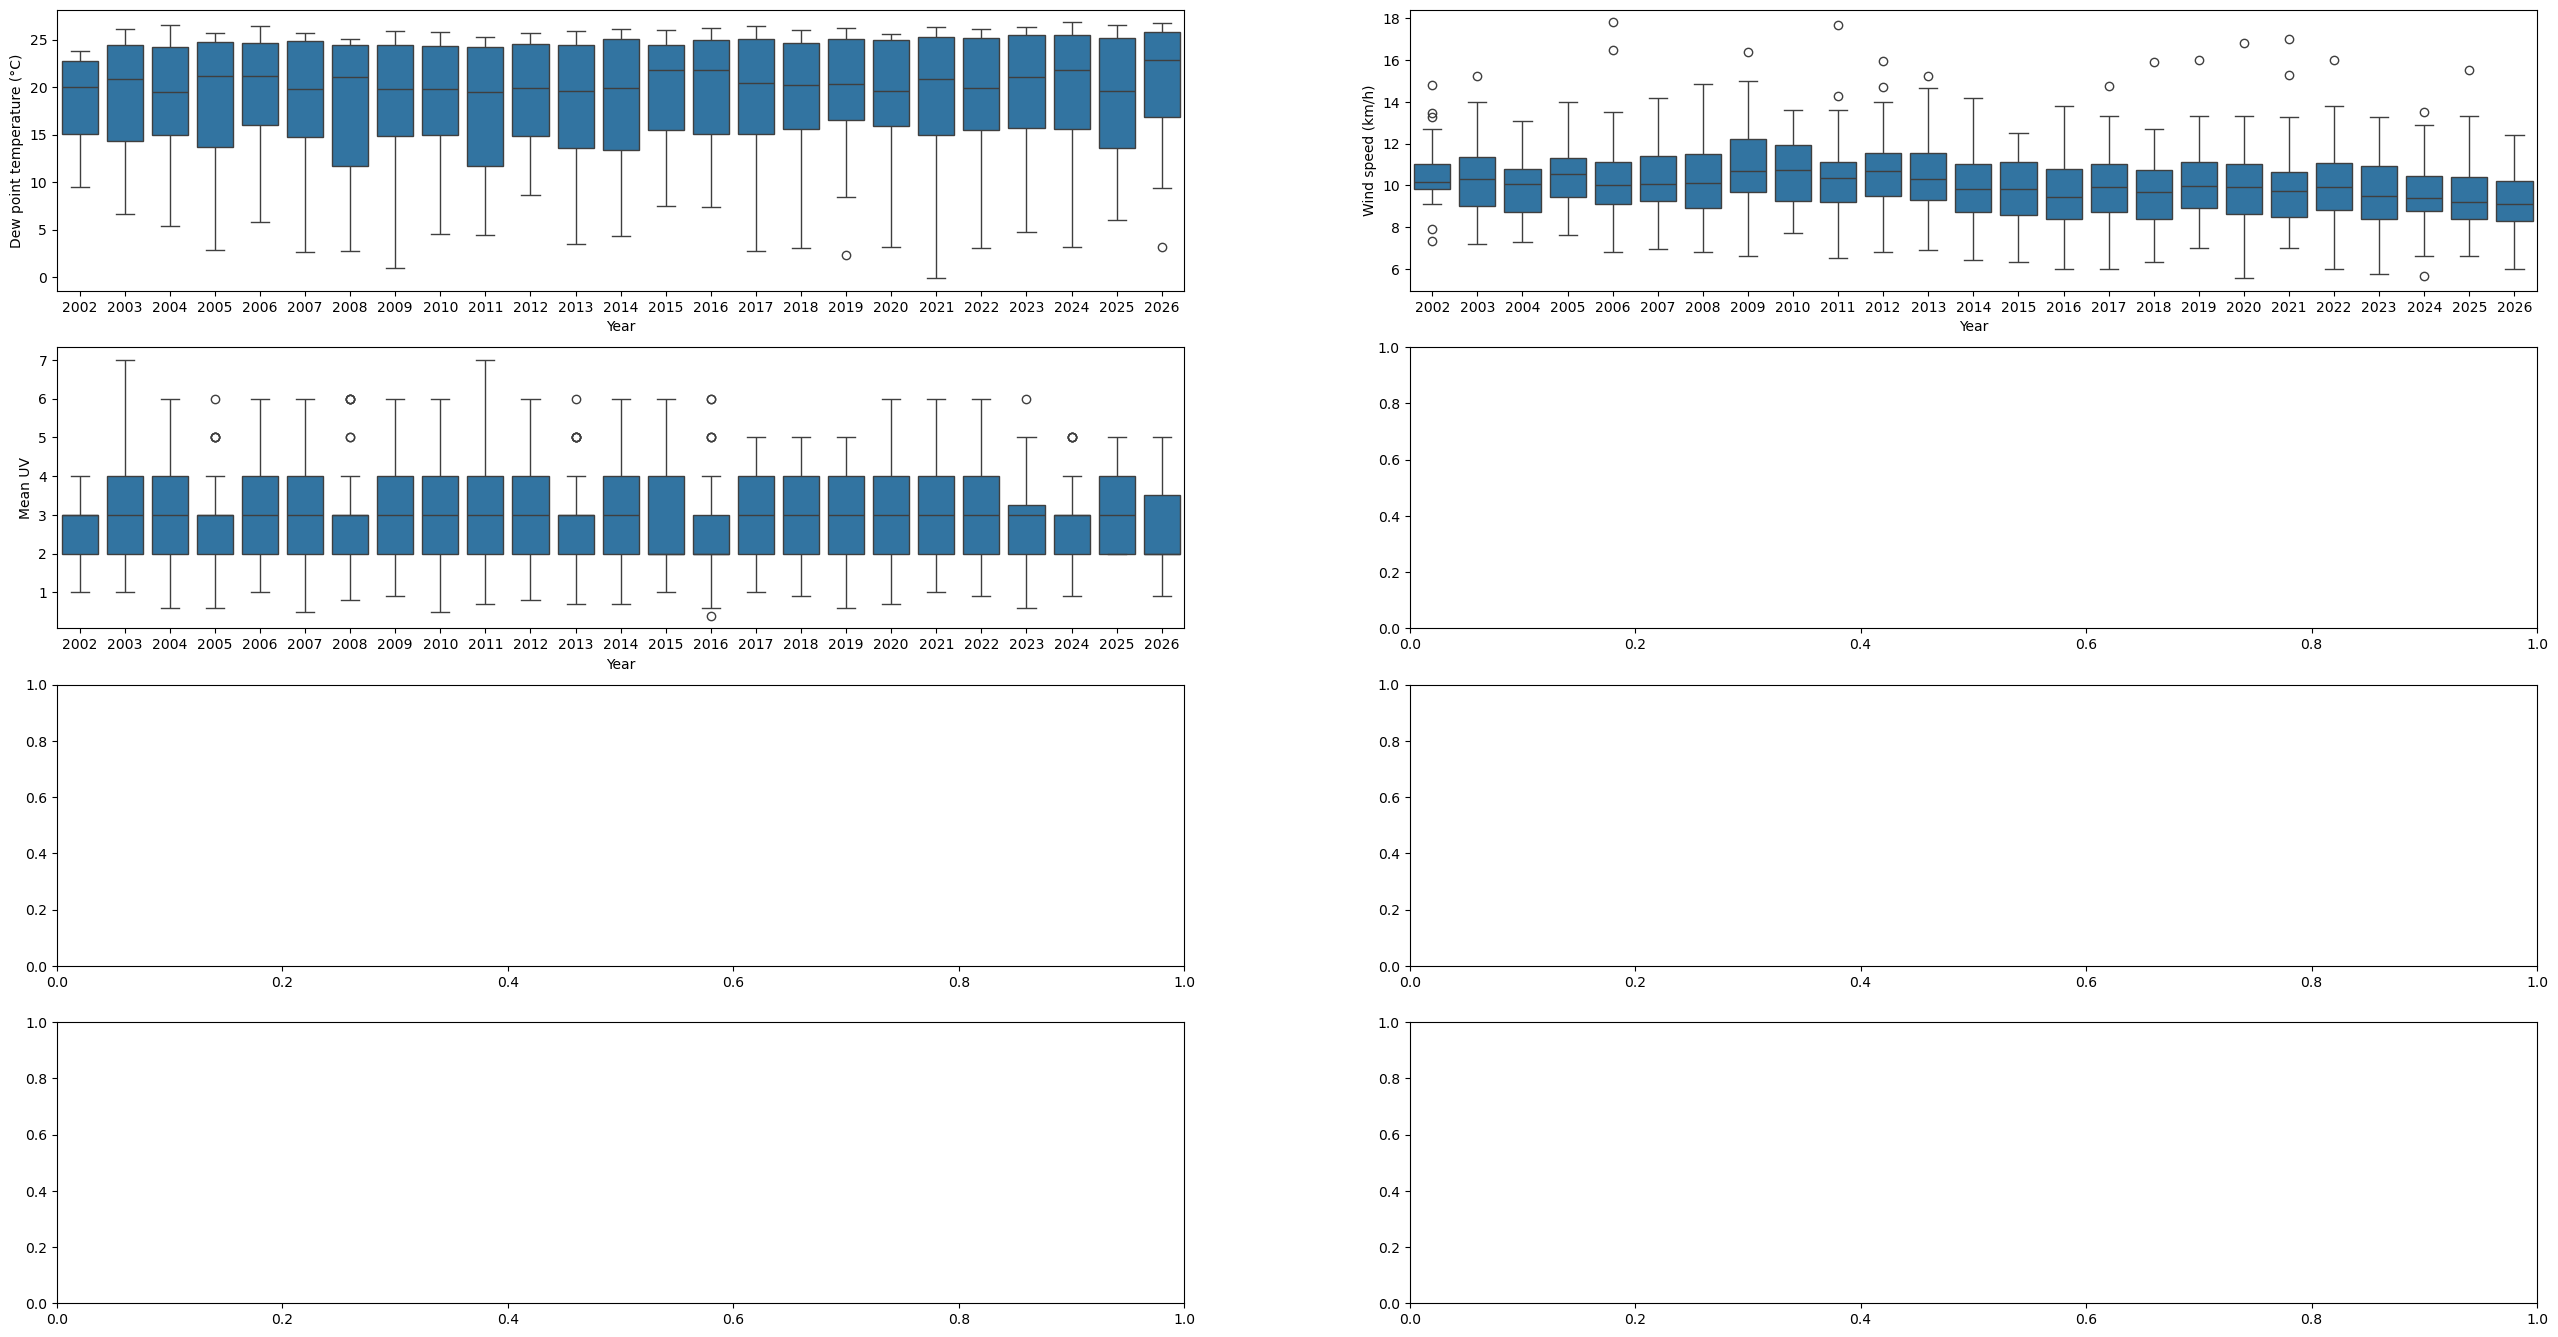

In [20]:
fig, axes = plt.subplots(4, 2, figsize=(6.4*5, 4.8*3.5))

for i, col in enumerate(mete_col):
    sns.boxplot(df[["Year", col]], x="Year", y=col, ax=axes[i//2, i%2])
    axes[i//2, i%2].set_xlabel("Year")
    axes[i//2, i%2].set_ylabel(col)

plt.show()